# Capstone project - Air passengers, start to finish

The course pipeline, on this series: explore it, decompose it, set the
benchmark floor, check what the floor leaves on the table, fit a model
through the framework, cross-validate, and read the result against the
floor.

**What is graded is the process, not the number.** A low MASE from one
holdout with no intervals scores worse than an honest analysis that
concludes the benchmark wins.

Full rules and report requirements: `brief.md`. Grading: `rubric.md`. This
notebook is the first deliverable; it should run top to bottom in under ten
minutes on Colab.

This notebook is a starter. You may swap in your own series or your own
framework - see "Your own data or method" in `brief.md`.

In [1]:
import sys

if "google.colab" in sys.modules:
    !git clone -q https://github.com/Ahmed-Bah/Global-CO2-Forecasting.git /content/proj
    %cd /content/proj
    !pip install -q -e .

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from coursekit import plotting as P
from coursekit import scoring

P.use_course_style()

SEASON_LENGTH = 12
H = 12            # forecast horizon for cross-validation
H_REPORT = 24     # forecast horizon for the report

/content/proj
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Installing backend dependencies ... done
  Preparing editable metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 501.8/501.8 kB 19.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.7/348.7 kB 23.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 281.0/281.0 kB 20.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.4/50.4 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.9/59.9 kB 4.6 MB/s eta 0:00:00
  Building editable for international-airpassengers-project (pyproject.toml) ... done


/content/proj/coursekit/plotting.py:599: SyntaxWarning: invalid escape sequence '\h'
  :math:`\hat{F}` whose characteristics do not change over time -- so that a
/content/proj/coursekit/plotting.py:676: SyntaxWarning: invalid escape sequence '\h'
  """Draw the h-step errors :math:`e_{t+h|t} = y_{t+h} - \hat{y}_{t+h|t}`.


---
# 0. The data

Monthly global mean atmospheric CO2 (ppm), 1979-03 to 2026-06: 568
observations, no gaps. Source: NOAA Global Monitoring Laboratory
(`co2.global.csv` via NOAA PSL), cached in `data/co2_global_monthly.csv`.

The most recent months are provisional and get revised, so no conclusion
here rests on the last two or three points.


In [2]:
raw = pd.read_csv("data/co2_global_monthly.csv", parse_dates=["date"])
df = pd.DataFrame({
    "unique_id": "Global CO2 (NOAA GML)",
    "ds": raw["date"],
    "y": raw["co2_ppm"].astype(float),
}).sort_values("ds").reset_index(drop=True)
df.head()


,unique_id,ds,y
0,Global CO2 (NOAA GML),1979-03-01,336.56
1,Global CO2 (NOAA GML),1979-04-01,337.29
2,Global CO2 (NOAA GML),1979-05-01,337.88
3,Global CO2 (NOAA GML),1979-06-01,338.32
4,Global CO2 (NOAA GML),1979-07-01,338.26


In [3]:
# Confirm the calendar.

n_obs = len(df)
range_ = (df["ds"].min(), df["ds"].max())
n_gaps = len(pd.date_range(range_[0], range_[1], freq="MS")) - n_obs
print(f"{n_obs} months, {range_[0].date()} to {range_[1].date()}, {n_gaps} gaps")

568 months, 1979-03-01 to 2026-06-01, 0 gaps


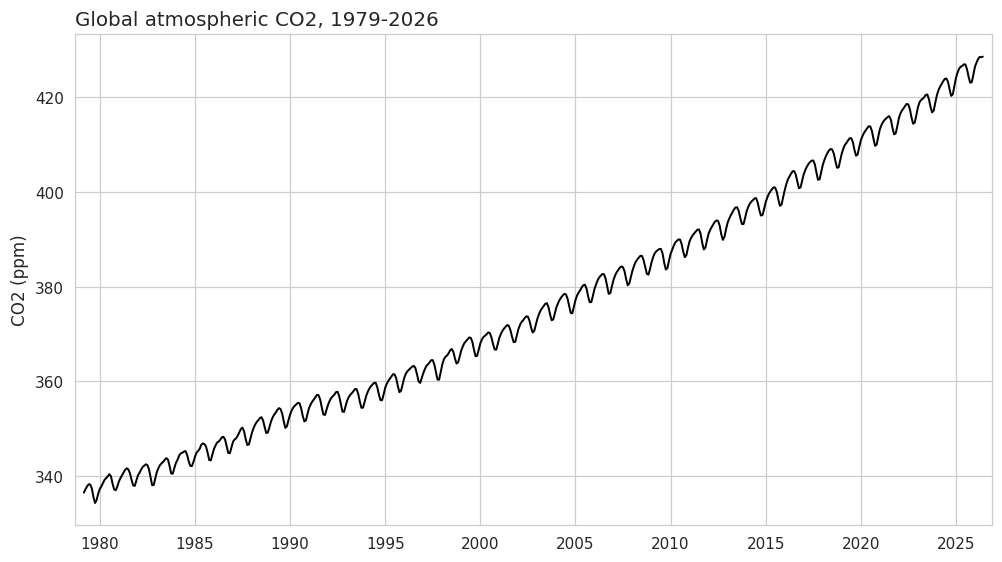

In [4]:
P.plot_series(df, title="Global atmospheric CO2, 1979-2026",
              ylabel="CO2 (ppm)", xlabel="")
plt.show()


**First read.** Before any model, write two sentences that describe this
series in plain language - the kind a non-forecaster could repeat. (Trend?
Seasonality? What happens to the swings as the level grows? Cycle?) These two
sentences belong at the top of your report.

The series rises steadily (about 337 to 429 ppm) with a regular yearly cycle of roughly 5 ppm peak to trough. The swings stay the same size as the level grows, so the seasonality is additive.

---
# 1. Exploration and shape

The Day 1 toolkit, in order. Every chart should carry its claim: a title that
says what it shows, not just "series".

**1.1 Decompose.** STL, additive, period 12. Read all three panels: which
component does the work, and what does the remainder look like?

The trend does most of the work (337 to 429 ppm). The seasonal part is a steady 5 ppm yearly cycle. The remainder is small (std 0.13) and looks like noise.

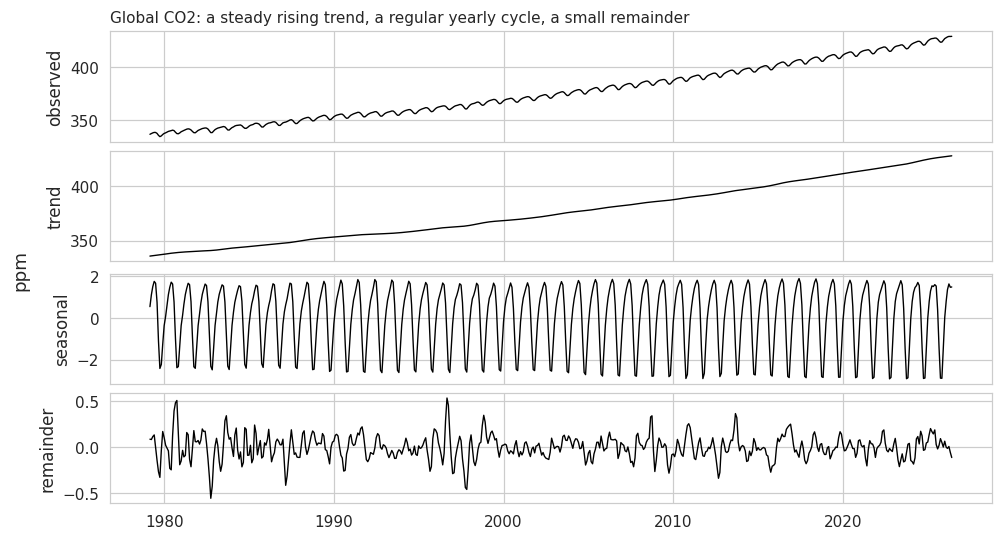

In [5]:
# STL decomposition (statsmodels), additive, period=12.

from statsmodels.tsa.seasonal import STL

res = STL(df["y"], period=SEASON_LENGTH).fit()
dcmp = pd.DataFrame({
    "ds": df["ds"],
    "observed": df["y"],
    "trend": res.trend,
    "seasonal": res.seasonal,
    "remainder": res.resid,
})
P.decomposition_plot(dcmp, cols=["observed", "trend", "seasonal", "remainder"],
                     title="Global CO2: a steady rising trend, a regular yearly cycle, a small remainder",
                     ylabel="ppm", x="ds")
plt.show()

**1.2 Trend and seasonal strength.** The two numbers from Day 1, computed
the same way (textbook formulas on the STL components). State what they
imply for model choice.

Trend strength is 1.00 and seasonal strength is 0.99, so both matter. The model needs a trend term and a seasonal term.

In [6]:
# trend_strength and seasonal_strength from the STL components.

trend_strength = max(0, 1 - dcmp["remainder"].var() / (dcmp["trend"] + dcmp["remainder"]).var())
seasonal_strength = max(0, 1 - dcmp["remainder"].var() / (dcmp["seasonal"] + dcmp["remainder"]).var())
print(f"trend strength: {trend_strength:.2f}")
print(f"seasonal strength: {seasonal_strength:.2f}")

trend strength: 1.00
seasonal strength: 0.99


**1.3 Autocorrelation.** The ACF of the raw series. What is at lag 12?
At 24? What does that tell you before you fit anything?

At lag 12 the ACF is 0.93 and at lag 24 it is 0.87. It just decays slowly from 1, with no spike at 12. The trend is so strong that it hides the yearly pattern. So the model has to deal with the trend first, and it still needs a seasonal part.

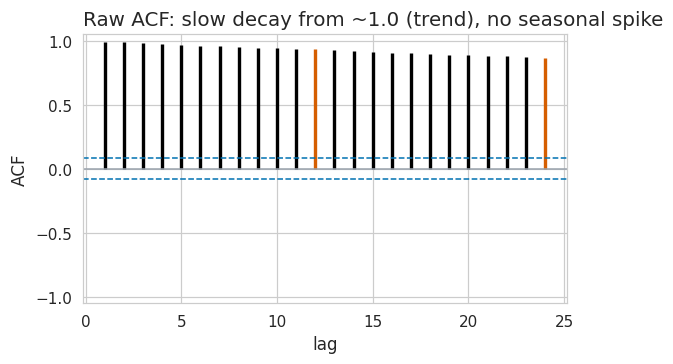

In [7]:
# ACF plot of df["y"] (P.acf_plot), 24 lags.

P.acf_plot(df["y"], nlags=24, highlight_every=SEASON_LENGTH,
           title="Raw ACF: slow decay from ~1.0 (trend), no seasonal spike")
plt.show()

---
# 2. The floor

The seasonal naive is the first model you fit on any series - not as a
formality, as the thing everything else has to beat. Fit it, check what it
leaves on the table, and give it an honest interval.

In [8]:
from statsforecast import StatsForecast
from statsforecast.models import SeasonalNaive

floor_sf = StatsForecast(models=[SeasonalNaive(season_length=SEASON_LENGTH)],
                         freq="MS", n_jobs=1)
floor_fc = floor_sf.forecast(df=df, h=H_REPORT, level=scoring.LEVELS)
floor_fc.head()

,unique_id,ds,SeasonalNaive,SeasonalNaive-lo-20,SeasonalNaive-lo-40,SeasonalNaive-lo-60,SeasonalNaive-lo-80,SeasonalNaive-lo-95,SeasonalNaive-hi-20,SeasonalNaive-hi-40,SeasonalNaive-hi-60,SeasonalNaive-hi-80,SeasonalNaive-hi-95
0,Global CO2 (NOAA GML),2026-07-01,426.90,426.381078,425.825888,425.176135,424.275041,422.885471,427.418922,427.974112,428.623865,429.524959,430.914529
1,Global CO2 (NOAA GML),2026-08-01,425.89,425.371078,424.815888,424.166135,423.265041,421.875471,426.408922,426.964112,427.613865,428.514959,429.904529
2,Global CO2 (NOAA GML),2026-09-01,424.27,423.751078,423.195888,422.546135,421.645041,420.255471,424.788922,425.344112,425.993865,426.894959,428.284529
3,Global CO2 (NOAA GML),2026-10-01,423.06,422.541078,421.985888,421.336135,420.435041,419.045471,423.578922,424.134112,424.783865,425.684959,427.074529
4,Global CO2 (NOAA GML),2026-11-01,423.18,422.661078,422.105888,421.456135,420.555041,419.165471,423.698922,424.254112,424.903865,425.804959,427.194529


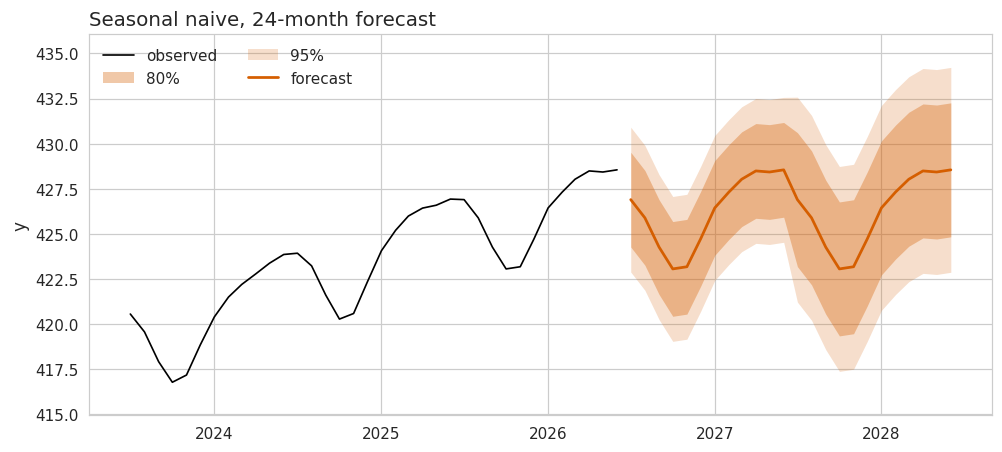

In [9]:
P.fan_chart(df, floor_fc.rename(columns={
            "SeasonalNaive": "mean",
            "SeasonalNaive-lo-20": "lo-20",
            "SeasonalNaive-lo-40": "lo-40",
            "SeasonalNaive-lo-60": "lo-60",
            "SeasonalNaive-lo-80": "lo-80",
            "SeasonalNaive-lo-95": "lo-95",
            "SeasonalNaive-hi-20": "hi-20",
            "SeasonalNaive-hi-40": "hi-40",
            "SeasonalNaive-hi-60": "hi-60",
            "SeasonalNaive-hi-80": "hi-80",
            "SeasonalNaive-hi-95": "hi-95",
            "ds": "ds"}),
            title="Seasonal naive, 24-month forecast",
            history_tail=36, levels=(80, 95))
plt.show()

**2.1 What is left on the table.** The floor's in-sample residuals are
``y_t - y_{t-12}`` over the series. Plot them, then their ACF (24 lags). Is
there a trend left? Correlation at the low lags? At 12? If it is not white
noise, what structure is it, and which kind of model eats that structure?

Not white noise: residuals are mostly positive (mean +1.93 ppm) and slow-moving (lag-1 ACF 0.96, lag-12 0.27). That is a leftover trend, so a model with an adaptive trend (ETS or ARIMA with differencing) can absorb it.

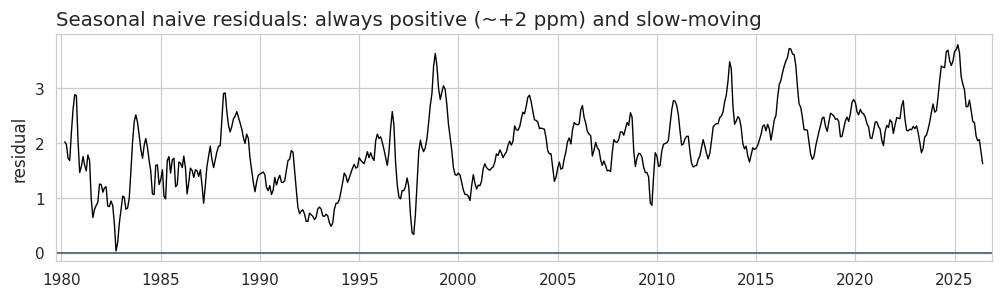

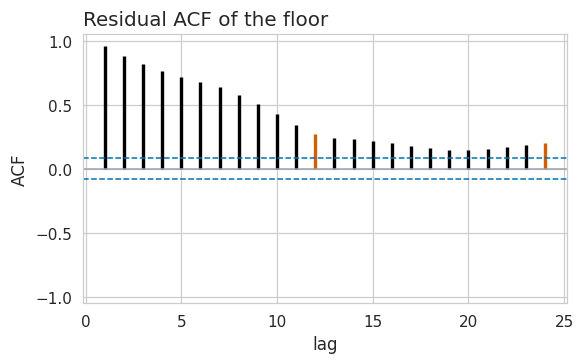

mean residual: 1.93   lag 1: 0.96   lag 12: 0.27   bound: ±0.083


In [10]:
resid_floor = (df["y"] - df["y"].shift(SEASON_LENGTH)).dropna()

P.residual_time_plot(resid_floor, ds=df["ds"],
                     title="Seasonal naive residuals: always positive (~+2 ppm) and slow-moving")
plt.show()
P.acf_plot(resid_floor, nlags=24, highlight_every=SEASON_LENGTH,
           title="Residual ACF of the floor")
plt.show()

r_res, bound_res = P.acf_values(resid_floor, nlags=24)
print(f"mean residual: {resid_floor.mean():.2f}   lag 1: {r_res[0]:.2f}   lag 12: {r_res[11]:.2f}   bound: ±{bound_res:.3f}")

---
# 3. Your model: the framework

AutoGluon fits a zoo of models behind one call - every model in the zoo
below is a model you have met in this course. The install is large, so this
runs on Colab.

> Every cell in this section is **skip-guarded**: without `autogluon`
> installed it prints why and moves on, so the rest of the notebook still
> runs.

In [11]:
!pip install -q autogluon.timeseries

import importlib.util

HAS_AG = importlib.util.find_spec("autogluon") is not None
if not HAS_AG:
    print("autogluon is not installed. On Colab, run this and re-run the cell:")
    print("    !pip install -q 'autogluon.timeseries'")
    print("\n(Takes a few minutes. A runtime reset wipes it.)")
else:
    print("autogluon is available")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 2.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 274.4/274.4 kB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.7/90.7 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 248.4/248.4 kB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 112.3/112.3 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 514.8/514.8 kB 27.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.8/80.8 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 285.4/285.4 kB 16.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 864.0/864.0 kB 28.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 34.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

**3.1 The data conversion stays visible.** AutoGluon has its own
frame, its own column names, its own fit loop and its own leaderboard.
Writing it out by hand once is the point - the gap between two APIs doing
the same job is the thing to notice.

| | this course | AutoGluon |
|---|---|---|
| id column | `unique_id` | `item_id` |
| time column | `ds` | `timestamp` |
| value column | `y` | `target` (nameable) |
| frame | `pd.DataFrame` | `TimeSeriesDataFrame` |

In [12]:
if HAS_AG:
    from autogluon.timeseries import TimeSeriesDataFrame, TimeSeriesPredictor

    # Long format to AutoGluon's long format: the same three columns, renamed.
    ag_long = df.rename(columns={"unique_id": "item_id", "ds": "timestamp"})
    tsdf = TimeSeriesDataFrame.from_data_frame(
        ag_long, id_column="item_id", timestamp_column="timestamp")

    # One 12-month holdout, cut the way AutoGluon expects.
    ag_train = tsdf.slice_by_timestep(None, -12)

    print(tsdf.head(3))
    print(f"\nfull: {len(tsdf)} rows   train: {len(ag_train)} rows")

                                       y
item_id               timestamp         
Global CO2 (NOAA GML) 1979-03-01  336.56
                      1979-04-01  337.29
                      1979-05-01  337.88

full: 568 rows   train: 556 rows


In [13]:
if HAS_AG:
    # Local models only - the same zoo this course taught, nothing neural.
    ZOO = {"Naive": {}, "SeasonalNaive": {}, "AutoETS": {},
           "AutoARIMA": {}, "Theta": {}}

    predictor = TimeSeriesPredictor(
        prediction_length=12, target="y", eval_metric="MASE",
        freq="MS", verbosity=1)
    predictor.fit(ag_train, hyperparameters=ZOO, time_limit=120)

In [14]:
if HAS_AG:
    lb = predictor.leaderboard(tsdf)
    display(lb)

,model,score_test,score_val,pred_time_test,pred_time_val,fit_time_marginal,fit_order
0,AutoETS,-0.122067,-0.437216,0.883544,0.993003,0.047832,4
1,AutoARIMA,-0.178073,-0.292769,2.634874,2.637373,0.039638,5
2,WeightedEnsemble,-0.189893,-0.274508,2.650533,2.674005,0.493135,6
3,Naive,-0.877218,-1.033681,0.013839,0.034469,0.062395,1
4,Theta,-1.219081,-1.865754,0.033200,0.068233,0.039951,3
5,SeasonalNaive,-1.219081,-1.865754,0.012511,0.022885,0.061028,2


**3.2 Read what it handed back.** What is the *sign* of `score_val`, and
what does the answer to "how many windows" mean for how much you should
trust this ranking? It decides what the next section does with this table.
And: does the shortlist agree with the shape you read in section 1?

`score_val` is negative because AutoGluon multiplies MASE by -1; closer to zero is better.
The ranking comes from a single 12-month window, so it is not a final verdict, only a way to build a shortlist. Evidence: the order differs between val (AutoARIMA first) and test (AutoETS first).
Shortlist: AutoETS and AutoARIMA. This agrees with section 1: models with an adaptive trend won, while Naive and SeasonalNaive came last.

---
# 4. The harness

The framework's ranking came from one internal split. One holdout is not a
ranking. So the shortlist goes through the rolling-origin harness: eight
origins, twelve months each, the whole distribution scored - and the floor
stays in the table.

In [15]:
sf_cv = StatsForecast(
    models=[SeasonalNaive(season_length=SEASON_LENGTH)],
    freq="MS", n_jobs=1)
cv = sf_cv.cross_validation(df=df, h=H, step_size=H, n_windows=8,
                            level=scoring.LEVELS)
cv.head()

,unique_id,ds,cutoff,y,SeasonalNaive,SeasonalNaive-lo-20,SeasonalNaive-lo-40,SeasonalNaive-lo-60,SeasonalNaive-lo-80,SeasonalNaive-lo-95,SeasonalNaive-hi-20,SeasonalNaive-hi-40,SeasonalNaive-hi-60,SeasonalNaive-hi-80,SeasonalNaive-hi-95
0,Global CO2 (NOAA GML),2018-07-01,2018-06-01,408.94,406.64,406.153689,405.633389,405.024469,404.180003,402.877759,407.126311,407.646611,408.255531,409.099997,410.402241
1,Global CO2 (NOAA GML),2018-08-01,2018-06-01,408.06,405.85,405.363689,404.843389,404.234469,403.390003,402.087759,406.336311,406.856611,407.465531,408.309997,409.612241
2,Global CO2 (NOAA GML),2018-09-01,2018-06-01,406.49,404.11,403.623689,403.103389,402.494469,401.650003,400.347759,404.596311,405.116611,405.725531,406.569997,407.872241
3,Global CO2 (NOAA GML),2018-10-01,2018-06-01,405.11,402.57,402.083689,401.563389,400.954469,400.110003,398.807759,403.056311,403.576611,404.185531,405.029997,406.332241
4,Global CO2 (NOAA GML),2018-11-01,2018-06-01,405.18,402.66,402.173689,401.653389,401.044469,400.200003,398.897759,403.146311,403.666611,404.275531,405.119997,406.422241


In [16]:
from statsforecast.models import AutoETS, RandomWalkWithDrift

MY_MODEL = AutoETS(season_length=SEASON_LENGTH)
MY_NAME = "AutoETS"

mysf = StatsForecast(models=[MY_MODEL], freq="MS", n_jobs=1)
mycv = mysf.cross_validation(df=df, h=H, step_size=H, n_windows=8, level=scoring.LEVELS)

drift_sf = StatsForecast(models=[RandomWalkWithDrift()], freq="MS", n_jobs=1)
drift_cv = drift_sf.cross_validation(df=df, h=H, step_size=H, n_windows=8, level=scoring.LEVELS)

RESULTS = pd.DataFrame({
    "SeasonalNaive": scoring.score_cv(cv, "SeasonalNaive", df),
    "RWD": scoring.score_cv(drift_cv, "RWD", df),
    MY_NAME: scoring.score_cv(mycv, MY_NAME, df),
}).T
RESULTS

,mase,rmsse,crps,coverage_80,mase_min,mase_max
SeasonalNaive,1.365614,1.293568,0.003343,0.604167,1.172938,1.865754
RWD,0.917450,1.169912,0.002967,0.697917,0.849712,1.002348
AutoETS,0.174359,0.189351,0.000520,0.750000,0.036850,0.437216


In [18]:
# The shortlist also had AutoARIMA: put it (and two more references) through the same harness.
from statsforecast.models import AutoARIMA, Naive

extra = StatsForecast(
    models=[AutoARIMA(season_length=SEASON_LENGTH), Naive()],
    freq="MS", n_jobs=1)
extra_cv = extra.cross_validation(df=df, h=H, step_size=H, n_windows=8, level=scoring.LEVELS)

cvs = {"SeasonalNaive": cv, "RWD": drift_cv, MY_NAME: mycv,
       "AutoARIMA": extra_cv, "Naive": extra_cv}
RESULTS_ALL = pd.DataFrame({m: scoring.score_cv(c, m, df) for m, c in cvs.items()}).T
RESULTS_ALL["width80"] = [(c[f"{m}-hi-80"] - c[f"{m}-lo-80"]).mean() for m, c in cvs.items()]
RESULTS_ALL.round(4).sort_values("mase")

,mase,rmsse,crps,coverage_80,mase_min,mase_max,width80
AutoARIMA,0.1635,0.1790,0.0004,0.9167,0.0645,0.2977,1.2069
AutoETS,0.1744,0.1894,0.0005,0.7500,0.0369,0.4372,0.8933
RWD,0.9174,1.1699,0.0030,0.6979,0.8497,1.0023,5.7775
Naive,0.9670,1.0977,0.0027,0.7500,0.8772,1.0535,5.8194
SeasonalNaive,1.3656,1.2936,0.0033,0.6042,1.1729,1.8658,5.0425


In [19]:
SHIP = "AutoARIMA"
ship_cv = extra_cv

err = ship_cv["y"] - ship_cv[SHIP]
width80 = (ship_cv[f"{SHIP}-hi-80"] - ship_cv[f"{SHIP}-lo-80"]).mean()
step = ship_cv.groupby(["unique_id", "cutoff"]).cumcount() + 1

print(f"mean error (y - forecast): {err.mean():.3f} ppm")
print(f"mean 80% band width: {width80:.2f} ppm")
print(f"coverage: 80% band {scoring.coverage(ship_cv, SHIP, level=80):.3f}, 95% band {scoring.coverage(ship_cv, SHIP, level=95):.3f}")
print("mean abs error by horizon step (ppm):")
print(err.abs().groupby(step).mean().round(2).to_string())

mean error (y - forecast): 0.068 ppm
mean 80% band width: 1.21 ppm
coverage: 80% band 0.917, 95% band 1.000
mean abs error by horizon step (ppm):
1     0.09
2     0.19
3     0.18
4     0.20
5     0.27
6     0.29
7     0.32
8     0.33
9     0.36
10    0.41
11    0.49
12    0.52


**4.1 Read the table.** Does the harness confirm the leaderboard's
shortlist, or does it move it? For each model: where does it beat the
floor, where does it lose, and on which of the three metrics? A model that
wins the point forecast and loses the distribution is a real result -
report both halves. And what does each model's 80% coverage say about its
band?

The harness confirms the shortlist and ranks it. AutoARIMA (MASE 0.16) and AutoETS (0.17) both beat the floor (1.37) on MASE and CRPS, and even AutoARIMA's worst window (0.30) beats the floor's best (1.17). Random walk with drift and naive also beat the floor on MASE, but by less. The two leaders are close on accuracy; the difference is the band: AutoETS covers 75% (too narrow), AutoARIMA covers 92% (too wide, but on the safe side).

---
# 5. The report

The notebook is evidence; the report is the claim. Two to three pages, for a
manager who will not open the notebook:

- **The recommendation.** Which model you would ship, in one sentence, and
  the one number that earns it.
- **The intervals.** How wide, what they covered, and whether the band is
  honest. Coverage is the check a band cannot do alone.
- **The residuals.** What the floor - and your model - missed. A residual
  ACF is a fact; a sentence about what it means is the deliverable.
- **One change.** A specific next step - data, driver, frequency, horizon -
  and what you expect it to do.

Rules: every number in the report comes out of this notebook; no number
that could not have come out of the harness counts; no leakage - a fold's
fit and its denominator use only data that fold was allowed to see.

**Optional, for extra credit.** The series is a total across origins, so a
driver is a modelling choice, not a lookup: pick a region and pull its
monthly mean temperature from a public weather archive (for example
Open-Meteo's historical API - free, no key), cache it next to the CSV, and
regress on it. That is dynamic regression - and the cross-validation
discipline still applies to the regression's residuals.